In [2]:
import requests
import pandas as pd
import numpy as np

result = requests.get("https://api.mfapi.in/mf/search", params={"q": "Aditya Birla Large Cap"})
schemes = pd.DataFrame(result.json())

# show only Direct Growth plans
schemes[schemes["schemeName"].str.contains("Direct", case=False) &
        schemes["schemeName"].str.contains("Growth", case=False)]

,schemeCode,schemeName
5,119436,Aditya Birla Sun Life Large & Mid Cap Fund - D...
7,119528,Aditya Birla Sun Life Large Cap Fund - Direct ...


In [3]:
code = 119528   # <-- put your scheme code here

data = requests.get(f"https://api.mfapi.in/mf/{code}").json()
df = pd.DataFrame(data["data"])

df["date"] = pd.to_datetime(df["date"], format="%d-%m-%Y")
df["nav"] = df["nav"].astype(float)
df = df.sort_values("date").set_index("date")

df = df[df.index >= "2021-11-10"]   # keep the last 5 years

df.tail()

,nav
date,
2026-11-03,567.74
2026-11-04,572.09
2026-11-05,584.88
2026-11-06,593.89
2026-11-09,596.18


<Axes: title={'center': 'NAV over the last 5 years'}, xlabel='date'>

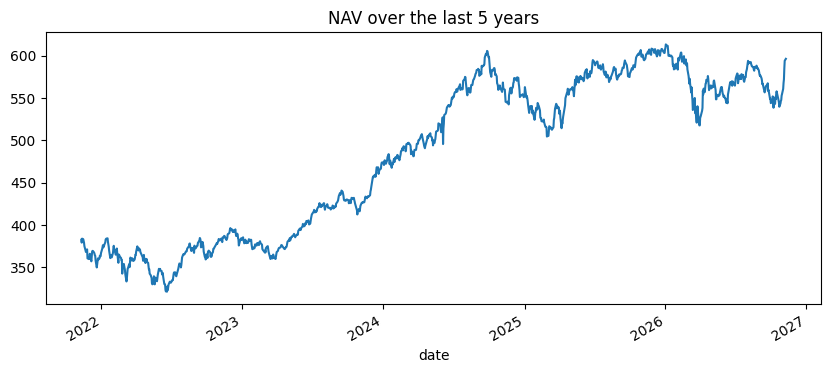

In [4]:
df["daily_return"] = df["nav"].pct_change()

df["nav"].plot(title="NAV over the last 5 years", figsize=(10, 4))

CAGR:          9.28%
Volatility:    13.39%
Sharpe ratio:  0.21
Max drawdown:  -16.68%


<Axes: title={'center': 'Drawdown from peak'}, xlabel='date'>

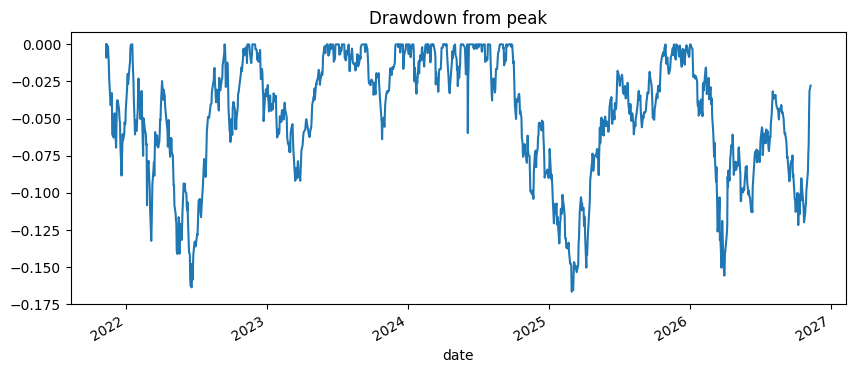

In [5]:
# 1. Return (CAGR)
years = (df.index[-1] - df.index[0]).days / 365.25
cagr = (df["nav"].iloc[-1] / df["nav"].iloc[0]) ** (1 / years) - 1

# 2. Volatility (annualised)
volatility = df["daily_return"].std() * np.sqrt(252)

# 3. Sharpe ratio (assuming 6.5% risk-free rate)
risk_free = 0.065
sharpe = (cagr - risk_free) / volatility

# 4. Maximum drawdown
running_peak = df["nav"].cummax()
drawdown = df["nav"] / running_peak - 1
max_drawdown = drawdown.min()

print(f"CAGR:          {cagr:.2%}")
print(f"Volatility:    {volatility:.2%}")
print(f"Sharpe ratio:  {sharpe:.2f}")
print(f"Max drawdown:  {max_drawdown:.2%}")

drawdown.plot(title="Drawdown from peak", figsize=(10, 4))